# Get Started
Learn how to install QuantLib and create your first QuantLib objects.

## Setup your virtual environment and install Quantlib
- Create a virtual environment using the following command from the repo root: -m venv .venv
- Activate the virtual environment to install packages by running .venv\Scripts\activate
- install QuantLib in your own virtual environment: run pip install QuantLib
- Select the virtual environment as python kernel by CTRL + SHIFT + P > select kernel or by changing it on the top right of this file in VS code
- Run the code below to see if it's correctly installed. 

In [2]:
import QuantLib as ql

Now also install and load some other packages. Also install the openpyxl package. 

In [3]:
import numpy as np
import pandas as pd
import datetime as dt
import os
import matplotlib.pyplot as plt

And some specific functions

In [4]:
from pathlib import Path

## Intro to Quantlib
QuantLib is a C++ library for financial quantitative analysts and developers. 

Some websites that can be useful:
- https://quantlib-python-docs.readthedocs.io/en/latest/ contains the most important python functionality explanation
- https://github.com/lballabio/QuantLib contains the QuantLib package source code (in C++)
- https://www.quantlib.org/reference/index.html contains the C++ reference manual
- https://github.com/OpenSourceRisk/ORE-SWIG/tree/master/OREAnalytics-SWIG/Python contains the source code for the Python SWIG (Simplified Wrapper and Interface Generator) to make C++ functionality available in python



## Date objects in QuantLib

You can create a QuantLib date object as follows:

In [5]:
myDate = ql.Date(14,8,2026)
print(myDate)

todaysDate = ql.Date.todaysDate()
print(todaysDate)

August 14th, 2026
August 25th, 2026


It's possible to increase your date by a specific period such as days, months or years. 

In [6]:
print(f'Add one day: {myDate + ql.Period(1, ql.Days)}')
print(f'Add one month: {myDate + ql.Period(1, ql.Months)}')
print(f'Add one year: {myDate + ql.Period(1, ql.Years)}')

Add one day: August 15th, 2026
Add one month: September 14th, 2026
Add one year: August 14th, 2027


But sometimes you need to adjust your date based on a certain amount of business days given a specific calendar. For example, the general European market calendar 'Target'. 

The variable myDate is 14th of August 2026, which is a Friday. Adding one day will result in a weekend day, which is not included in the target calendar because markets are closed. You can adjust by one business day using the ql.TARGET() calendar, which directly takes into account that the market is closed on weekend days.

In [7]:
myCalendar = ql.TARGET()
myCalendar.advance(myDate, 1, ql.Days)

Date(17,8,2026)

Finally, you can also specify a global variable called 'evaluationDate'. This variable defines the date as of which you're doing your analysis. For example, if you'd like to price a financial instrument as of last monday, you can set your global evaluation date on that specific date. 

In [8]:
evaluationDate = ql.Date(14,8,2026)

# set global evaluation date:
ql.Settings.instance().evaluationDate = evaluationDate

print(f'Global evaluation date set to: {ql.Settings.instance().evaluationDate}')

Global evaluation date set to: August 14th, 2026


## Explore the data
This project contains several data sets. We'll start with two data sets that will be used to create swap term structures. These files will be used in the first examples:
- data/6M EURIBOR 20260820.xlsx
- data/ESTR 20260820.xlsx

First open the excel files to explore the data. Then load the data into python with the code below.

In [9]:
# The data is in the data folder of this project
data_directory = Path.cwd().parents[1] / "data"
euribor_file = data_directory / "6M EURIBOR 20260820.xlsx"
ESTR_file    = data_directory / "ESTR 20260820.xlsx"

In [20]:
# load the data
ESTR_data = pd.read_excel(ESTR_file, 
                          sheet_name="Piecewise Lin. (Simp)",
                          skiprows=8)
ESTR_data.head(5)

,Term,Market Rate,Shift,Shifted Rate,Zero Rate,Discount,Year Fraction
0,1 WK,2.18905,0,2.18905,2.21925,0.999331,0.019231
1,2 WK,2.18975,0,2.18975,2.21933,0.998906,0.038462
2,1 MO,2.25200,0,2.25200,2.27406,0.997822,0.083333
3,2 MO,2.34415,0,2.34415,2.36276,0.995672,0.166667
4,3 MO,2.38560,0,2.38560,2.40340,0.993699,0.250000


The loaded ESTR data contains market rates for ESTR swaps, as well as their corresponding zero and discount rates. Let's plot the market rates to visualize the values.

Text(0, 0.5, 'Market rate (%)')

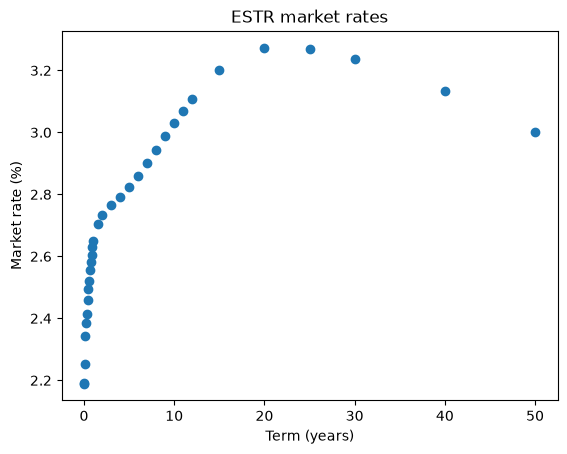

In [11]:
plt.plot(ESTR_data['Year Fraction'], ESTR_data['Market Rate'],marker='o', linestyle='')
plt.title('ESTR market rates')
plt.xlabel('Term (years)')
plt.ylabel('Market rate (%)')

# Exercise
Now you have seen how to work with dates in QuantLib and you've explored the data. To put this into practice, you can do the following assignment. Add a new column to the ESTR_data that contains the maturity date as a quantlib date for each row. 

The maturity date is computed as todays date plus the term. So for example, if today is August 20th, 2026, then the corresponding maturity date for the first row is one week later, which is August 27th, 2026.

In [12]:
# Add your implementation here.

## Working with quotes and handles in QuantLib
QuantLib uses SimpleQuote objects instead of raw numbers because market data can change. When a quote is updated, all dependent curves, instruments, and risk measures can automatically reprice without rebuilding the entire object structure.

This so-called 'observer pattern' is one of QuantLib's core design principles.

In QuantLib, we have both quotes and handles. A quote stores the actual market value, such as a swap rate of 3.00% or a bond yield of 2.75%. A handle, on the other hand, acts as a smart reference to that quote, also called a 'pointer'. Rather than passing market data directly to curves and instruments, QuantLib passes handles that maintain the connection between dependent objects and the underlying market data. 

The main advantage of the handle structure, is that once you update your quotes, all dependent objects such as curves and financial instruments will change alongside without you overwriting these existing objects. 

We can see this with the following example. You create a quote object with a specified value. Then you create a handle that's pointing to this quote object. If you set the value of the quote object to a different value, the handle will understand that this value has changed. 

In [17]:
quote_value = 1

quote_object = ql.SimpleQuote(quote_value)

quote_handle = ql.QuoteHandle(quote_object)

print(f'Current quote value: {quote_object.value()}')
print(f'Current quote handle: {quote_handle.value()}')

Current quote value: 1.0
Current quote handle: 1.0


Now change the value of the quote object without specifically changing the value of the handle. You'll see that the value of the handle will adjust to the new quote value. 

In [18]:
quote_object.setValue(2)
print(f'New quote value: {quote_object.value()}')
print(f'Current quote handle: {quote_handle.value()}')

New quote value: 2.0
Current quote handle: 2.0


This is a simple example of how to use quotes and handles. Throughout this project, you'll see plenty of usecases where this functionality of QuantLib is used. Now try it yourself. Change the value of the quote and check if the handle changes as well. 

In [ ]:
# Your implementation here.